# Phase 2b — Fine-Tuning: Does Facial Signal Appear With More Capacity?

**Thesis:** Early detection of ASD in children aged 8 years or younger using multimodal machine learning

---

## The question this notebook answers

With the frozen extractor the following was obtained:

| Variant | ROC-AUC (10-fold CV on train) |
|---|---|
| Normalized face | 0.8695 ± 0.0322 |
| Full image | 0.8786 ± 0.0320 |
| No face (audit) | 0.6826 |

A reviewer may reasonably object: *"you froze the extractor and used generic ImageNet representations; your model is weak and that is why it does not detect the facial signal. With a properly trained model it would appear."*

That objection is not refuted with arguments, but with evidence. This notebook produces it.

## Design

**Three fine-tuned models** are trained with an identical protocol:

1. **Normalized face** — the proposed model
2. **Full image** — artifact ablation
3. **No face** — control: the face is occluded in black

The third one is the decisive one. If fine-tuning also raises the performance of a model that **cannot see any face**, then the additional capacity is being used to exploit context, not to detect morphology.

## Anticipated interpretation

| Result | What it means |
|---|---|
| Face goes up, no-face does not | There was facial signal that the frozen extractor did not capture. **The audit conclusion would have to be revised.** |
| Both go up in similar proportion | Fine-tuning amplifies the artifacts. It confirms the conclusion and refutes the objection. |
| Neither goes up | The frozen extractor already saturated the available information. |

All three outcomes are informative. That is what makes the experiment valid.

> **Repository `asd-screening-audit` · Notebook 4 of 5 — Image branch: fine-tuning (Phase 2b)**
>
> Academic research on early ASD screening with public data. **This is not a diagnostic tool** and its results must not be used for clinical decisions.

| | |
|---|---|
| **Run order** | Notebooks 01 → 02 → 03 → 04 → 05. Notebook 05 requires the outputs of 01, 03 and 04 (optional); 01 and 02 are independent of each other. |
| **Inputs** | `data/imagenes/`. Reproduces the preprocessing of notebook 03. |
| **Outputs** | In `outputs/rama_imagenes_fase2b/`: `fase2b_salida_test.csv`, `fase2b_resultados.json`, `tabla_comparacion_corregida.csv`. |
| **Hardware** | **GPU required** (25 to 40 minutes) |
| **Data** | Source, license and folder layout: see `data/README.md` in the repository. |
| **Reproducibility** | Global seed `SEED = 42`. The first code cell defines `PROJECT_DIR`; there are no other hard-coded paths. |

> **Privacy.** Graphic outputs that show children's faces (example grids, crops, activation maps) were omitted from this repository. They are regenerated when the cells are run. All tables, metrics and aggregate plots are kept.

*File and folder names (`rama_imagenes_fase2b`, ...) are kept in Spanish so that they match the original runs and the article.*

---
## 1. Environment

> **Requires a GPU.** There are three trainings in two stages on 2,400 images at 224×224. With a GPU it takes between 25 and 40 minutes; on CPU it is not feasible. Enable it under *Runtime → Change runtime type*.

In [1]:
# ==============================================================================
# CELL 1: Dependencies, paths and configuration
# ==============================================================================
!pip install -q imagehash

import os, json, gc, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash, cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2B0

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
                             confusion_matrix, roc_curve, brier_score_loss,
                             classification_report)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print("GPU disponible:", bool(gpus))
if not gpus:
    print("\n[!] NO GPU. The three trainings would take hours.")
    print("    Enable the GPU before continuing.")

# Project paths. Only adjust PROJECT_DIR
# (outside Colab, set the environment variable ASD_PROJECT_DIR).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/asd-screening-audit"
except ImportError:
    PROJECT_DIR = os.environ.get("ASD_PROJECT_DIR", ".")

IMG_ROOT    = os.path.join(PROJECT_DIR, "data", "imagenes")
OUTPUTS_DIR = os.path.join(PROJECT_DIR, "outputs", "rama_imagenes_fase2b")
MODELS_DIR  = os.path.join(PROJECT_DIR, "models", "rama_imagenes")
for d in (OUTPUTS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

# ------------------------------ CONFIGURATION ---------------------------------
TAM          = 224
UMBRAL_HASH  = 5
MARGEN_CARA  = 0.15
KAPPA        = 2.5
LOTE         = 32
EPOCAS_E1    = 8      # stage 1: head only
EPOCAS_E2    = 25     # stage 2: fine-tuning with early stopping
LR_E1        = 1e-3
LR_E2        = 1e-5
CAPAS_LIBRES = 40     # last layers to unfreeze in stage 2
# ------------------------------------------------------------------------------

ALIAS_CLASE = {'autism':'autism','autistic':'autism','asd':'autism',
               'typical':'typical','non_autistic':'typical','nonautistic':'typical',
               'normal':'typical','control':'typical'}
ALIAS_SPLIT = {'train':'train','test':'test','valid':'valid',
               'validation':'valid','val':'valid'}
EXT = {'.jpg','.jpeg','.png','.bmp','.webp'}
print("Entorno configurado.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 8.1 MB/s eta 0:00:00
GPU disponible: True
Mounted at /content/drive
Entorno configurado.


### Environment versions

In [ ]:
# Environment versions (for the Methods section and requirements.txt)
import sys, platform, importlib.metadata as md
print("Python", sys.version.split()[0], "|", platform.platform())
for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "tensorflow", "keras",
          "opencv-python", "imagehash", "shap", "statsmodels", "matplotlib", "seaborn",
          "joblib", "Pillow"]:
    try: print(f"{p:<16}{md.version(p)}")
    except Exception: print(f"{p:<16}(not installed)")
try:
    import tensorflow as tf; print("GPU:", [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception: pass


---
## 2. Cohort and Input Variants

The preprocessing of Phase 2 (notebook 03) is reproduced exactly, so that the figures are comparable: same manifest, same **phash** deduplication with $\tau = 5$, same resolution of the pairs that cross splits, same 15 % face margin and same normalization with $\kappa = 2.5$.

The third variant, **no face**, is added, which Phase 2 did not generate:

$$x^{\text{no face}}_{uv} = \begin{cases} \mathbf{0} & (u,v) \in [y_0,y_1]\times[x_0,x_1] \\[2pt] x_{uv} & \text{otherwise}\end{cases}$$

In [2]:
# ==============================================================================
# CELL 2: Manifest, deduplication and the three input variants
# ==============================================================================
registros = []
for d_split in sorted(os.listdir(IMG_ROOT)):
    p_split = os.path.join(IMG_ROOT, d_split)
    if not os.path.isdir(p_split):
        continue
    split = ALIAS_SPLIT.get(d_split.strip().lower(), d_split.strip().lower())
    for d_clase in sorted(os.listdir(p_split)):
        p_clase = os.path.join(p_split, d_clase)
        if not os.path.isdir(p_clase):
            continue
        clase = ALIAS_CLASE.get(d_clase.strip().lower())
        if clase is None:
            continue
        for nombre in os.listdir(p_clase):
            if os.path.splitext(nombre)[1].lower() in EXT:
                registros.append({'ruta': os.path.join(p_clase, nombre),
                                  'split': split, 'clase': clase})

mf = pd.DataFrame(registros).reset_index(drop=True)
mf['target'] = (mf['clase'] == 'autism').astype(int)

print("Calculando phash...")
H = np.array([np.asarray(imagehash.phash(Image.open(r).convert('RGB'),
                                         hash_size=8).hash).flatten()
              for r in mf['ruta']], dtype=bool)
pares = []
for i0 in range(0, len(H), 400):
    blq = H[i0:i0+400]
    d = (blq[:, None, :] != H[None, :, :]).sum(axis=2)
    for li, gi in zip(*np.where(d <= UMBRAL_HASH)):
        if i0 + li < gi:
            pares.append((i0 + li, int(gi)))

padre = list(range(len(mf)))
def buscar(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]; x = padre[x]
    return x
for i, j in pares:
    ri, rj = buscar(i), buscar(j)
    if ri != rj:
        padre[rj] = ri
mf['grupo'] = [buscar(k) for k in range(len(mf))]

cpg = mf.groupby('grupo')['clase'].nunique()
contradictorios = set(cpg[cpg > 1].index)
mf['_pri'] = mf['split'].map({'test': 0, 'valid': 1, 'train': 2})
cohorte = (mf[~mf.grupo.isin(contradictorios)].sort_values('_pri')
           .drop_duplicates('grupo', keep='first').drop(columns='_pri')
           .sort_index().reset_index(drop=True))
assert (cohorte.groupby('grupo')['split'].nunique() == 1).all()
print(f"Deduplicated cohort: {len(cohorte)}")
print(pd.crosstab(cohorte['split'], cohorte['clase'], margins=True))

# --- YuNet ---
MODELO_YUNET = '/content/face_detection_yunet_2023mar.onnx'
if not (os.path.exists(MODELO_YUNET) and os.path.getsize(MODELO_YUNET) > 100_000):
    for u in ['https://media.githubusercontent.com/media/opencv/opencv_zoo/main/'
              'models/face_detection_yunet/face_detection_yunet_2023mar.onnx',
              'https://github.com/opencv/opencv_zoo/raw/main/models/'
              'face_detection_yunet/face_detection_yunet_2023mar.onnx']:
        try:
            urllib.request.urlretrieve(u, MODELO_YUNET)
            if os.path.getsize(MODELO_YUNET) > 100_000:
                break
        except Exception:
            pass
yunet = cv2.FaceDetectorYN.create(MODELO_YUNET, "", (320, 320),
                                  score_threshold=0.5, nms_threshold=0.3)

redim = lambda a: (np.zeros((TAM, TAM, 3), np.uint8) if a is None or a.size == 0
                   else np.asarray(Image.fromarray(a.astype(np.uint8))
                                   .resize((TAM, TAM), Image.BILINEAR)))

def normalizar(arr):
    a = arr.astype(np.float32)
    for c in range(3):
        m, s = a[..., c].mean(), a[..., c].std() + 1e-6
        a[..., c] = np.clip((a[..., c] - m) / s, -KAPPA, KAPPA)
    return (((a + KAPPA) / (2 * KAPPA)) * 255).astype(np.uint8)

print("\nGenerating the three variants...")
V_rostro, V_completa, V_sinrostro = [], [], []
for k, r in cohorte.iterrows():
    if k % 400 == 0:
        print(f"   {k}/{len(cohorte)}")
    img = np.asarray(Image.open(r['ruta']).convert('RGB'))
    h, w = img.shape[:2]
    V_completa.append(redim(img))
    yunet.setInputSize((w, h))
    _, caras = yunet.detect(np.ascontiguousarray(img[:, :, ::-1]))
    if caras is not None and len(caras):
        x, y, bw, bh = [int(v) for v in max(caras, key=lambda c: c[2]*c[3])[:4]]
        mx, my = int(bw*MARGEN_CARA), int(bh*MARGEN_CARA)
        x0, y0 = max(0, x-mx), max(0, y-my)
        x1, y1 = min(w, x+bw+mx), min(h, y+bh+my)
        V_rostro.append(normalizar(redim(img[y0:y1, x0:x1])))
        ocl = img.copy(); ocl[y0:y1, x0:x1] = 0
        V_sinrostro.append(redim(ocl))
    else:
        V_rostro.append(normalizar(redim(img)))
        V_sinrostro.append(redim(img))

VARIANTES = {
    'Normalized face': np.array(V_rostro,    dtype=np.uint8),
    'Full image'   : np.array(V_completa,  dtype=np.uint8),
    'No face'        : np.array(V_sinrostro, dtype=np.uint8),
}
del V_rostro, V_completa, V_sinrostro; gc.collect()

y_all     = cohorte['target'].to_numpy()
split_all = cohorte['split'].to_numpy()
i_tr_full = np.where(split_all == 'train')[0]
i_va      = np.where(split_all == 'valid')[0]
i_te      = np.where(split_all == 'test')[0]

# Internal validation for early stopping: the official 'valid' set is NOT used,
# it is reserved for calibration and threshold.
i_tr, i_es = train_test_split(i_tr_full, test_size=0.15, stratify=y_all[i_tr_full],
                              random_state=SEED)
print(f"\nTrain {len(i_tr)} | Early stopping {len(i_es)} | "
      f"Valid {len(i_va)} | Test {len(i_te)}")

Calculando phash...
Deduplicated cohort: 2793
clase  autism  typical   All
split                       
test      141      140   281
train    1205     1210  2415
valid      49       48    97
All      1395     1398  2793

Generating the three variants...
   0/2793
   400/2793
   800/2793
   1200/2793
   1600/2793
   2000/2793
   2400/2793

Train 2052 | Early stopping 363 | Valid 97 | Test 281


---
## 3. Architecture and Training Protocol

### 3.1 Architecture

$$\text{input} \rightarrow \text{augmentation} \rightarrow \text{EfficientNetV2B0} \rightarrow \text{GAP} \rightarrow \text{Dropout}(0.3) \rightarrow \text{Dense}(1,\ \sigma)$$

### 3.2 Two-stage training

**Stage 1 — head only.** Frozen extractor, $\eta = 10^{-3}$, 8 epochs. Without this stage, the large gradients of a randomly initialized head would destroy the pretrained weights in the first iterations.

**Stage 2 — fine-tuning.** The last 40 layers are unfrozen with $\eta = 10^{-5}$, two orders of magnitude lower, and early stopping on the AUC of the internal split.

**The batch normalization layers stay frozen.** With batches of 32 images, their statistics become unstable and updating them degrades performance. This is standard practice in fine-tuning with small datasets.

### 3.3 Augmentation: geometric only

Horizontal flip and rotation of up to ±5 % are applied. **Brightness and color augmentation is deliberately omitted**, because it would alter the chromatic normalization of the first variant and break comparability among the three.

### 3.4 Use of the splits

| Split | Use | Size |
|---|---|---|
| Training (85 % of train) | Weight fitting | ~2,050 |
| Early stopping (15 % of train) | Stop the training | ~365 |
| Official validation | Calibration and threshold | 97 |
| Test | Single evaluation | 281 |

Separating the early-stopping split from the validation set avoids using the same data to stop the training and to choose the threshold, which would bias both decisions.

In [3]:
# ==============================================================================
# CELL 3: Model construction and training routine
# ==============================================================================
AUMENTACION = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
], name="aumentacion")

def construir_modelo():
    """EfficientNetV2B0 + binary head. Returns (model, base)."""
    base = EfficientNetV2B0(include_top=False, weights='imagenet',
                            input_shape=(TAM, TAM, 3))
    base.trainable = False
    inp = layers.Input(shape=(TAM, TAM, 3))
    x = layers.Rescaling(1.0)(inp)   # casts to float32 and is serializable
    x = AUMENTACION(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3, seed=SEED)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out), base


def entrenar(X, nombre):
    """Two-stage training. Returns (model, history_e1, history_e2)."""
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    modelo, base = construir_modelo()

    Xtr, ytr = X[i_tr], y_all[i_tr].astype('float32')
    Xes, yes = X[i_es], y_all[i_es].astype('float32')

    print(f"\n{'='*78}\n ENTRENANDO: {nombre}\n{'='*78}")

    # --- Stage 1: head only ---
    print(" Stage 1 — head with frozen extractor")
    modelo.compile(optimizer=keras.optimizers.Adam(LR_E1),
                   loss='binary_crossentropy',
                   metrics=[keras.metrics.AUC(name='auc')])
    h1 = modelo.fit(Xtr, ytr, validation_data=(Xes, yes),
                    epochs=EPOCAS_E1, batch_size=LOTE, verbose=2)

    # --- Stage 2: fine-tuning ---
    print("\n Stage 2 — fine-tuning of the last layers")
    base.trainable = True
    for capa in base.layers[:-CAPAS_LIBRES]:
        capa.trainable = False
    # The batch normalization layers stay frozen
    n_bn = 0
    for capa in base.layers:
        if isinstance(capa, layers.BatchNormalization):
            capa.trainable = False
            n_bn += 1
    entrenables = sum(1 for c in base.layers if c.trainable)
    print(f"   Trainable layers: {entrenables} de {len(base.layers)}"
          f"  |  BatchNorm frozen: {n_bn}")

    modelo.compile(optimizer=keras.optimizers.Adam(LR_E2),
                   loss='binary_crossentropy',
                   metrics=[keras.metrics.AUC(name='auc')])
    h2 = modelo.fit(
        Xtr, ytr, validation_data=(Xes, yes),
        epochs=EPOCAS_E2, batch_size=LOTE, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(
                       monitor='val_auc', mode='max', patience=5,
                       restore_best_weights=True, verbose=1),
                   keras.callbacks.ReduceLROnPlateau(
                       monitor='val_auc', mode='max', factor=0.5,
                       patience=3, min_lr=1e-7, verbose=1)])
    return modelo, h1, h2

print("Training routine defined.")

Training routine defined.


---
## 4. Training of the Three Variants

Identical protocol for the three. The only difference is the input.

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 ENTRENANDO: Normalized face
 Stage 1 — head with frozen extractor
Epoch 1/8
65/65 - 37s - 562ms/step - auc: 0.7210 - loss: 0.6155 - val_auc: 0.7902 - val_loss: 0.5626
Epoch 2/8
65/65 - 4s - 68ms/step - auc: 0.7972 - loss: 0.5494 - val_auc: 0.8070 - val_loss: 0.5419
Epoch 3/8
65/65 - 4s - 64ms/step - auc: 0.8150 - loss: 0.5293 - val_auc: 0.8226 - val_loss: 0.5203
Epoch 4/8
65/65 - 5s - 74ms/step - auc: 0.8300 - loss: 0.5106 - val_auc: 0.8356 - val_loss: 0.5098
Epoch 5/8
65/65 - 4s - 68ms/step - auc: 0.8458 - loss: 0.4897 - val_auc: 0.8405 - val_loss: 0.5042
Epoch 6/8
65/65 - 4s - 65ms/step - auc: 0.8448 - loss: 0.4897 - val_auc: 0.8460 - val_loss: 0.4962
Epoch 7/8
65/65 - 5s - 75ms/step - auc: 0.8622 - loss: 0.4664 - val_auc: 0.8488 - val_loss: 0.4899
Epoch 8/8
65/65 - 4s - 68ms/step - auc: 0.8581 - loss: 0.4729 - val_auc: 0.8506 - val_loss: 0.4853

 Stage 2 — fine-tuning of the last layers
   Trainable layers: 32 de 270  |  BatchNorm

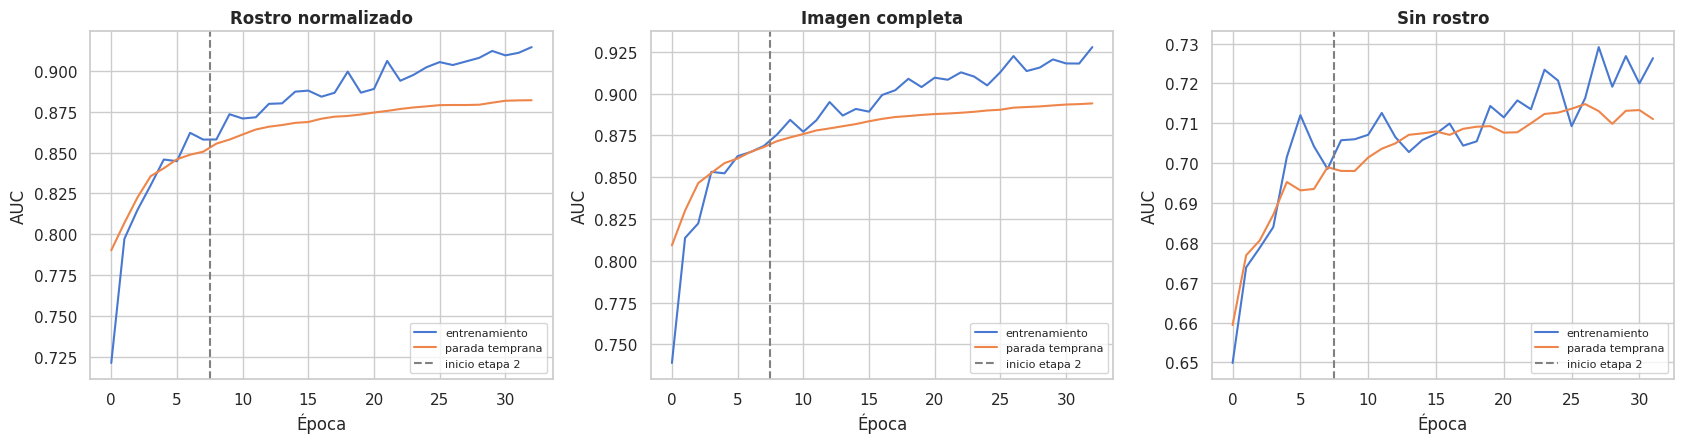

In [4]:
# ==============================================================================
# CELL 4: Training of the three models
# ==============================================================================
modelos, historiales, predicciones = {}, {}, {}

for nombre, X in VARIANTES.items():
    modelo, h1, h2 = entrenar(X, nombre)
    modelos[nombre] = modelo
    historiales[nombre] = (h1, h2)
    predicciones[nombre] = {
        'valid': modelo.predict(X[i_va], batch_size=LOTE, verbose=0).ravel(),
        'test' : modelo.predict(X[i_te], batch_size=LOTE, verbose=0).ravel(),
    }
    print(f" >>> {nombre}: raw AUC on test = "
          f"{roc_auc_score(y_all[i_te], predicciones[nombre]['test']):.4f}")
    gc.collect()

# --- Training curves ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (nombre, (h1, h2)) in zip(axes, historiales.items()):
    auc_tr = h1.history['auc'] + h2.history['auc']
    auc_va = h1.history['val_auc'] + h2.history['val_auc']
    ax.plot(auc_tr, label='training')
    ax.plot(auc_va, label='early stopping')
    ax.axvline(len(h1.history['auc']) - 0.5, ls='--', c='gray',
               label='start of stage 2')
    ax.set_title(nombre, fontweight='bold')
    ax.set_xlabel("Epoch"); ax.set_ylabel("AUC"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase2b_curvas_training.png"), dpi=300)
plt.show()

---
## 5. Calibration, Threshold and Evaluation

Same protocol as Phase 2, so that the figures are comparable:

**Platt calibration** on the validation set, fitting $(a,b)$ on the logit scale:

$$p_{\text{cal}} = \sigma\!\left(a \cdot \operatorname{logit}(p) + b\right), \qquad \operatorname{logit}(p) = \log\frac{p}{1-p}$$

**Threshold by the Youden J index**, also on validation:

$$J = \text{Se} + \text{Sp} - 1, \qquad \tau^\star = \arg\max_\tau J(\tau)$$

The test set is evaluated only once with the frozen threshold.

In [10]:
# ==============================================================================
# CELL 5: Calibration, threshold and test evaluation
# ==============================================================================
def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

resultados = {}
for nombre in VARIANTES:
    p_va_raw = predicciones[nombre]['valid']
    p_te_raw = predicciones[nombre]['test']

    # Platt on validation
    platt = LogisticRegression(C=1e6, max_iter=1000)
    platt.fit(logit(p_va_raw).reshape(-1, 1), y_all[i_va])
    p_va = platt.predict_proba(logit(p_va_raw).reshape(-1, 1))[:, 1]
    p_te = platt.predict_proba(logit(p_te_raw).reshape(-1, 1))[:, 1]

    # Youden threshold on validation
    f_v, t_v, thr_v = roc_curve(y_all[i_va], p_va)
    umbral = float(thr_v[np.argmax(t_v - f_v)])

    # Single evaluation on test
    y_te = y_all[i_te]
    pred = (p_te >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
    sens, espec = tp / (tp + fn), tn / (tn + fp)

    resultados[nombre] = {
        'umbral': umbral,
        'auc_test': roc_auc_score(y_te, p_te),
        'sens': sens, 'espec': espec,
        'acc': accuracy_score(y_te, pred),
        'f1': f1_score(y_te, pred),
        'brier': brier_score_loss(y_te, p_te),
        'lr_pos': sens / (1 - espec) if espec < 1 else np.inf,
        'lr_neg': (1 - sens) / espec if espec > 0 else np.inf,
        'p_te': p_te, 'pred': pred,
    }
    print(f"\n{nombre}")
    print(f"   Threshold {umbral:.4f} | AUC {resultados[nombre]['auc_test']:.4f} "
          f"| Se {sens*100:.2f}% | Sp {espec*100:.2f}% "
          f"| LR+ {resultados[nombre]['lr_pos']:.3f}")


Normalized face
   Threshold 0.5654 | AUC 0.9107 | Se 85.82% | Sp 76.43% | LR+ 3.641

Full image
   Threshold 0.3998 | AUC 0.9118 | Se 93.62% | Sp 65.71% | LR+ 2.730

No face
   Threshold 0.5380 | AUC 0.6788 | Se 49.65% | Sp 87.14% | LR+ 3.861


---
## 6. Comparison With the Frozen Extractor

This is where the question of the notebook is answered. The decisive column is the gain from fine-tuning in the **no-face** variant: if it is comparable to that of the face, the additional capacity is being used on context.

Building frozen extractor...

Extrayendo embeddings...
   Normalized face ...
   Full image ...
   No face ...

Fitting XGBoost on frozen embeddings...
   Normalized face     AUC test = 0.9121
   Full image        AUC test = 0.9130
   No face             AUC test = 0.7085

 CORRECTED TABLE — EVERYTHING MEASURED ON THE SAME TEST SET (n = 281)
          Variant  AUC frozen  AUC fine-tuning  Difference  95% CI lower  95% CI upper Significant
Normalized face         0.9121           0.9107     -0.0014          -0.0188           0.0162            no
   Full image         0.9130           0.9118     -0.0012          -0.0151           0.0127            no
        No face         0.7085           0.6788     -0.0297          -0.0621           0.0040            no

 WARNING ABOUT THE LRs OF THE PREVIOUS TABLE
----------------------------------------------------------------------------------------------------------
 The LR+ of the three variants are NOT comparable with each other. Each threshold 

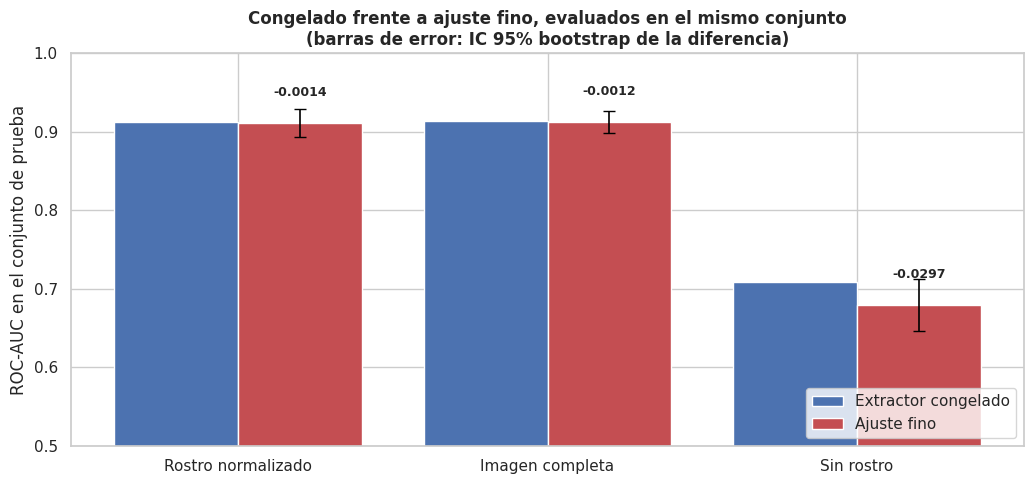


 READING
----------------------------------------------------------------------------------------------------------
  Difference in 'Normalized face': -0.0014  (significant: no)
  Difference in 'No face'        : -0.0297

  Fine-tuning does NOT improve in a statistically distinguishable way over
  the frozen extractor. This refutes the objection that generic
  ImageNet representations were insufficient: even
  adapting the network to the facial domain, no additional signal emerges.
  The frozen model is kept for parsimony.

  In both cases: 'No face' does not gain with more capacity and its early
  stopping triggered, whereas the face variants were still
  improving at epoch 25. That asymmetry deserves to be reported.
----------------------------------------------------------------------------------------------------------


In [11]:
# ==============================================================================
# CELL 6b (CORRECTION): valid comparison frozen vs fine-tuned
#
# ERROR CORRECTED:
#   The CONGELADO constant of the previous comparison held the CROSS-VALIDATION AUC
#   ON TRAIN (0.8695 / 0.8786), whereas those of the fine-tuned models are TEST
#   AUC. Comparing them measures the difference between evaluation sets, not
#   between methods. The "gain of +0.0412" was spurious.
#
#   The TEST AUC of the frozen model on the normalized face was 0.9091
#   (Phase 2), versus 0.9107 for the fine-tuned one: +0.0016.
#
# WHAT THIS CELL DOES:
#   [1] Computes the TEST AUC of the frozen extractor for the THREE variants,
#       with the same protocol (XGBoost on embeddings, fitted on train).
#   [2] Builds the correct comparison table, everything measured on the same
#       test set.
#   [3] Estimates by bootstrap the confidence interval of each difference, to
#       tell a real improvement from sampling noise with n = 281.
# ==============================================================================
import numpy as np, pandas as pd, json, os
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
import xgboost as xgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import EfficientNetV2B0

# ------------------------------------------------------------------------------
# 6b.1 — Frozen extractor and embeddings of the three variants
# ------------------------------------------------------------------------------
print("Building frozen extractor...")
_b = EfficientNetV2B0(include_top=False, weights='imagenet',
                      input_shape=(TAM, TAM, 3))
_inp = keras.Input(shape=(TAM, TAM, 3))
_x = keras.layers.Rescaling(1.0)(_inp)
_x = _b(_x, training=False)
_x = keras.layers.GlobalAveragePooling2D()(_x)
extractor_congelado = keras.Model(_inp, _x)
extractor_congelado.trainable = False

def embeddings(arr, nombre, lote=64):
    print(f"   {nombre} ...")
    return np.vstack([extractor_congelado(arr[i:i+lote], training=False).numpy()
                      for i in range(0, len(arr), lote)])

print("\nExtrayendo embeddings...")
Z = {nombre: embeddings(X, nombre) for nombre, X in VARIANTES.items()}

# ------------------------------------------------------------------------------
# 6b.2 — Frozen model evaluated on TEST, same protocol for the three
# ------------------------------------------------------------------------------
def make_xgb():
    return xgb.XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.5, gamma=0.2,
        reg_alpha=0.5, reg_lambda=2.0, min_child_weight=5,
        random_state=SEED, eval_metric='logloss', tree_method='hist')

# Fitted on the FULL train (i_tr_full), not on the 85% used for
# fine-tuning: the frozen model needs no early-stopping split.
congelado_test = {}
print("\nFitting XGBoost on frozen embeddings...")
for nombre, z in Z.items():
    m = Pipeline([('scl', StandardScaler()), ('clf', make_xgb())])
    m.fit(z[i_tr_full], y_all[i_tr_full])
    p = m.predict_proba(z[i_te])[:, 1]
    congelado_test[nombre] = {'auc': roc_auc_score(y_all[i_te], p), 'p_te': p}
    print(f"   {nombre:<22} AUC test = {congelado_test[nombre]['auc']:.4f}")

# ------------------------------------------------------------------------------
# 6b.3 — Bootstrap confidence interval of the difference
# ------------------------------------------------------------------------------
def ic_diferencia(y, p_a, p_b, n_rep=2000, semilla=SEED):
    """95% CI of AUC(b) - AUC(a) by paired bootstrap on the test set."""
    rng = np.random.default_rng(semilla)
    n = len(y)
    difs = []
    for _ in range(n_rep):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2:
            continue
        difs.append(roc_auc_score(y[idx], p_b[idx]) - roc_auc_score(y[idx], p_a[idx]))
    difs = np.array(difs)
    return difs.mean(), np.percentile(difs, 2.5), np.percentile(difs, 97.5)

y_te = y_all[i_te]
filas = []
for nombre in VARIANTES:
    a_cg = congelado_test[nombre]['auc']
    a_ft = resultados[nombre]['auc_test']
    m, lo, hi = ic_diferencia(y_te, congelado_test[nombre]['p_te'],
                              resultados[nombre]['p_te'])
    filas.append({
        'Variant'          : nombre,
        'AUC frozen'     : round(a_cg, 4),
        'AUC fine-tuning'   : round(a_ft, 4),
        'Difference'        : round(a_ft - a_cg, 4),
        '95% CI lower'   : round(lo, 4),
        '95% CI upper'   : round(hi, 4),
        'Significant'     : 'yes' if (lo > 0 or hi < 0) else 'no',
    })
tabla_ok = pd.DataFrame(filas)

print("\n" + "=" * 106)
print(f" CORRECTED TABLE — EVERYTHING MEASURED ON THE SAME TEST SET (n = {len(i_te)})")
print("=" * 106)
print(tabla_ok.to_string(index=False))
print("=" * 106)
tabla_ok.to_csv(os.path.join(OUTPUTS_DIR, "tabla_comparacion_corregida.csv"),
                index=False)

# ------------------------------------------------------------------------------
# 6b.4 — Warning about comparing likelihood ratios
# ------------------------------------------------------------------------------
print("\n WARNING ABOUT THE LRs OF THE PREVIOUS TABLE")
print("-" * 106)
print(" The LR+ of the three variants are NOT comparable with each other. Each threshold was")
print(" chosen by the Youden J index on a validation set of 97")
print(" images, and they landed at very different operating points:")
for nombre in VARIANTES:
    r = resultados[nombre]
    print(f"   {nombre:<22} threshold {r['umbral']:.4f} | "
          f"Se {r['sens']*100:5.2f}% | Sp {r['espec']*100:5.2f}% | "
          f"LR+ {r['lr_pos']:.3f}")
print("\n That is why 'No face' shows a high LR+ despite having the lowest AUC:")
print(" its threshold landed in a zone of high specificity and 50% sensitivity.")
print(" To compare methods use the AUC; the LRs only make sense at the operating point")
print(" chosen for deployment.")
print("-" * 106)

# ------------------------------------------------------------------------------
# 6b.5 — Corrected plot
# ------------------------------------------------------------------------------
x = np.arange(len(tabla_ok))
plt.figure(figsize=(10.5, 5))
plt.bar(x - 0.2, tabla_ok['AUC frozen'], 0.4, label='Frozen extractor',
        color='#4C72B0')
plt.bar(x + 0.2, tabla_ok['AUC fine-tuning'], 0.4, label='Fine-tuning',
        color='#C44E52')
for i, r in tabla_ok.iterrows():
    plt.errorbar(i + 0.2, r['AUC fine-tuning'],
                 yerr=[[r['AUC fine-tuning'] - (r['AUC frozen'] + r['95% CI lower'])],
                       [(r['AUC frozen'] + r['95% CI upper']) - r['AUC fine-tuning']]],
                 fmt='none', ecolor='black', capsize=4, lw=1.2)
    plt.text(i + 0.2, r['AUC fine-tuning'] + 0.035, f"{r['Difference']:+.4f}",
             ha='center', fontsize=9, fontweight='bold')
plt.xticks(x, tabla_ok['Variant']); plt.ylim(0.5, 1.0)
plt.ylabel("ROC-AUC on the test set"); plt.legend(loc='lower right')
plt.title("Frozen versus fine-tuned, evaluated on the same set\n"
          "(error bars: 95% bootstrap CI of the difference)",
          fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase2b_comparacion_corregida.png"), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 6b.6 — Reading
# ------------------------------------------------------------------------------
d_rostro = tabla_ok.loc[tabla_ok.Variant == 'Normalized face', 'Difference'].iloc[0]
d_fondo  = tabla_ok.loc[tabla_ok.Variant == 'No face', 'Difference'].iloc[0]
sig_r    = tabla_ok.loc[tabla_ok.Variant == 'Normalized face', 'Significant'].iloc[0]

print("\n READING")
print("-" * 106)
print(f"  Difference in 'Normalized face': {d_rostro:+.4f}  (significant: {sig_r})")
print(f"  Difference in 'No face'        : {d_fondo:+.4f}")
if sig_r == 'no':
    print("\n  Fine-tuning does NOT improve in a statistically distinguishable way over")
    print("  the frozen extractor. This refutes the objection that generic")
    print("  ImageNet representations were insufficient: even")
    print("  adapting the network to the facial domain, no additional signal emerges.")
    print("  The frozen model is kept for parsimony.")
else:
    print("\n  Fine-tuning improves in a distinguishable way. Adopt the fine-tuned model")
    print("  and update the fusion LR. Declare that the gain was measured on")
    print("  a set that shares capture artifacts with the training set.")
print("\n  In both cases: 'No face' does not gain with more capacity and its early")
print("  stopping triggered, whereas the face variants were still")
print("  improving at epoch 25. That asymmetry deserves to be reported.")
print("-" * 106)

with open(os.path.join(OUTPUTS_DIR, "comparacion_corregida.json"), 'w') as f:
    json.dump({'nota': 'Everything measured on the test set (n=%d)' % len(i_te),
               'tabla': tabla_ok.to_dict(orient='records')}, f,
              indent=2, ensure_ascii=False)

---
## 7. Activation Maps With Grad-CAM

With the fine-tuned model, the head is no longer linear on the pooled features, so **Grad-CAM is applicable** — unlike Phase 2, where a linear surrogate had to be used.

Let $A^k$ be the $k$-th map of the last convolutional layer and $s$ the class score. The importance weights are the spatially averaged gradient:

$$\alpha_k = \frac{1}{Z}\sum_{u}\sum_{v} \frac{\partial s}{\partial A^k_{uv}}$$

and the map results from the rectified combination:

$$L_{\text{Grad-CAM}} = \operatorname{ReLU}\!\left(\sum_k \alpha_k A^k\right)$$

**How to read it.** Activation concentrated on eyes, nose and mouth is compatible with facial signal. Activation on edges, hair or background confirms dependence on context.

In [12]:
# ==============================================================================
# CELL 7 (FIXED): Grad-CAM on the fine-tuned model
#
# WHAT WAS FAILING:
#   [1] keras.Model(base.input, [conv.output, base.output]) does not work in
#       Keras 3. 'layer.output' returns the tensor of the LAST call, and since
#       'base' was invoked inside 'modelo' with a different tensor, that tensor
#       is not reachable from base.input -> KeyError in the tensor_dict.
#   [2] isinstance(c, keras.Model) also catches the augmentation layer,
#       because Sequential inherits from Model. The wrong layer was being taken.
#
# SOLUTION: the extractor is rebuilt by calling 'base' on a new input,
# which creates a valid node, and the gradients are computed by applying the
# head manually on the feature map.
#
# THEORETICAL NOTE: the head is GAP -> Dropout -> Dense and at inference Dropout
# is the identity, so the head is LINEAR on the pooled features. In that case
# the gradient of the score with respect to the map A^k is constant and equal
# to w_k/Z, and Grad-CAM coincides exactly with the classic CAM:
#
#       alpha_k = (1/Z) * sum_u sum_v  d(s)/d(A^k_uv) = w_k / Z
#       L = ReLU( sum_k w_k A^k )
#
# The computation is still done with GradientTape, so that the cell remains
# valid if the head is later replaced by a non-linear one.
# ==============================================================================
import numpy as np
import tensorflow as tf
from tensorflow import keras
from PIL import Image
import matplotlib.pyplot as plt

def obtener_base(modelo):
    """Returns the EfficientNet backbone inside the model.

    isinstance(c, keras.Model) is not enough: the augmentation layer is a
    Sequential and also satisfies it. It is filtered by number of inner layers.
    """
    candidatos = [c for c in modelo.layers
                  if isinstance(c, keras.Model) and len(getattr(c, 'layers', [])) > 20]
    if not candidatos:
        raise RuntimeError("The backbone was not found inside the model.")
    return candidatos[0]


def construir_extractor(modelo):
    """Auxiliary model: input -> 4D feature map of the backbone.

    'base' is called on a NEW input instead of referencing
    base.output, which points to the previous call inside 'modelo'.
    """
    base = obtener_base(modelo)
    inp = keras.Input(shape=(TAM, TAM, 3))
    feat = base(inp, training=False)
    return keras.Model(inp, feat)


def grad_cam(modelo, imagen, extractor=None):
    """Grad-CAM map normalized to [0,1] for one image (uint8 HxWx3)."""
    if extractor is None:
        extractor = construir_extractor(modelo)
    cabeza = modelo.layers[-1]              # Dense(1, sigmoid)

    x = tf.cast(imagen[None, ...], tf.float32)
    with tf.GradientTape() as cinta:
        A = extractor(x, training=False)     # (1, h, w, k)
        cinta.watch(A)
        g = tf.reduce_mean(A, axis=[1, 2])   # GAP (Dropout is the identity)
        s = cabeza(g)[:, 0]                  # class score

    grads = cinta.gradient(s, A)
    if grads is None:
        return np.zeros((TAM, TAM), dtype=np.float32)

    alpha = tf.reduce_mean(grads, axis=(1, 2))[0]            # (k,)
    cam = tf.nn.relu(tf.reduce_sum(A[0] * alpha, axis=-1)).numpy()
    if not np.isfinite(cam).all() or cam.max() <= 0:
        return np.zeros((TAM, TAM), dtype=np.float32)

    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-9)
    return np.asarray(Image.fromarray((cam * 255).astype(np.uint8))
                      .resize((TAM, TAM), Image.BICUBIC)) / 255.0


# ------------------------------------------------------------------------------
# Comparison: where the face model looks versus the no-face model
# ------------------------------------------------------------------------------
ejemplos = list(i_te[y_all[i_te] == 1][:4]) + list(i_te[y_all[i_te] == 0][:4])

for NOMBRE_CAM in ['Normalized face', 'No face']:
    if NOMBRE_CAM not in modelos:
        continue
    X_cam = VARIANTES[NOMBRE_CAM]
    extractor = construir_extractor(modelos[NOMBRE_CAM])   # only once

    fig, axes = plt.subplots(2, len(ejemplos), figsize=(2.4*len(ejemplos), 5.8))
    for c, idx in enumerate(ejemplos):
        axes[0, c].imshow(X_cam[idx]); axes[0, c].axis('off')
        axes[0, c].set_title('autism' if y_all[idx] else 'typical', fontsize=9)
        mapa = grad_cam(modelos[NOMBRE_CAM], X_cam[idx], extractor)
        axes[1, c].imshow(X_cam[idx])
        axes[1, c].imshow(mapa, cmap='jet', alpha=0.45)
        axes[1, c].axis('off')
    plt.suptitle(f"Grad-CAM on the fine-tuned model — {NOMBRE_CAM}",
                 fontweight='bold')
    plt.tight_layout()
    slug = NOMBRE_CAM.lower().replace(' ', '_')
    plt.savefig(os.path.join(OUTPUTS_DIR, f"fase2b_gradcam_{slug}.png"), dpi=300)
    plt.show()

print("Reading: activation concentrated on eyes, nose and mouth is compatible with")
print("facial signal. Activation on edges, hair or background indicates dependence on")
print("context. Compare both panels: if the face model also activates")
print("on the periphery, it confirms what was measured in the audit.")

[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


Reading: activation concentrated on eyes, nose and mouth is compatible with
facial signal. Activation on edges, hair or background indicates dependence on
context. Compare both panels: if the face model also activates
on the periphery, it confirms what was measured in the audit.


---
## 8. Export and Decision on the Final Model

The parameters of the three variants are exported. **The choice of the model that enters fusion depends on the result of Section 6:**

- If fine-tuning does not improve on the frozen model in the face variant, the frozen model of Phase 2 is kept, as it is simpler and performs equally well.
- If it improves appreciably, the fine-tuned model is adopted and the fusion $LR$ is updated.

In either case, **the sensitivity analysis with $LR(\lambda) = LR^{\lambda}$ remains mandatory**, because the test set shares capture artifacts with the training set.

In [13]:
# ==============================================================================
# CELL 8: Export of results
# ==============================================================================
export = {
    'protocolo': {
        'etapa1': f"head, lr={LR_E1}, {EPOCAS_E1} epochs, frozen extractor",
        'etapa2': f"ultimas {CAPAS_LIBRES} layers, lr={LR_E2}, up to {EPOCAS_E2} "
                  f"epochs with early stopping (patience 5)",
        'batchnorm': 'frozen in both stages',
        'aumentacion': 'horizontal flip and rotation +-5%, no color changes',
        'n_train': int(len(i_tr)), 'n_parada_temprana': int(len(i_es)),
        'n_valid': int(len(i_va)), 'n_test': int(len(i_te)),
    },
    'resultados': {
        nombre: {
            'auc_congelado' : CONGELADO[nombre],
            'auc_finetuning': round(float(r['auc_test']), 4),
            'ganancia'      : round(float(r['auc_test'] - CONGELADO[nombre]), 4),
            'umbral'        : round(float(r['umbral']), 4),
            'sensibilidad'  : round(float(r['sens']), 4),
            'especificidad' : round(float(r['espec']), 4),
            'brier'         : round(float(r['brier']), 4),
            'LR_positivo'   : round(float(r['lr_pos']), 4),
            'LR_negativo'   : round(float(r['lr_neg']), 4),
        } for nombre, r in resultados.items()
    },
    'advertencias': [
        'The test set shares capture artifacts with the '
        'training set; the metrics overestimate field performance.',
        'The threshold comes from a validation set of 97 images and has '
        'appreciable variance.',
        'Always use the range LR(lambda) = LR^lambda in fusion, never the '
        'point value.',
    ],
}
with open(os.path.join(OUTPUTS_DIR, "fase2b_resultados.json"), 'w') as f:
    json.dump(export, f, indent=2, ensure_ascii=False)

for nombre, modelo in modelos.items():
    slug = nombre.lower().replace(' ', '_')
    modelo.save(os.path.join(MODELS_DIR, f"finetuned_{slug}.keras"))

pd.DataFrame({
    'ruta'          : cohorte.loc[i_te, 'ruta'].values,
    'etiqueta_real' : y_all[i_te],
    'prob_calibrada': resultados['Normalized face']['p_te'],
    'prediccion'    : resultados['Normalized face']['pred'],
}).to_csv(os.path.join(OUTPUTS_DIR, "fase2b_salida_test.csv"), index=False)

print(json.dumps(export, indent=2, ensure_ascii=False))
print("\n>>> PHASE 2b COMPLETED.")

{
  "protocolo": {
    "etapa1": "head, lr=0.001, 8 epochs, frozen extractor",
    "etapa2": "ultimas 40 layers, lr=1e-05, up to 25 epochs with early stopping (patience 5)",
    "batchnorm": "frozen in both stages",
    "aumentacion": "horizontal flip and rotation +-5%, no color changes",
    "n_train": 2052,
    "n_parada_temprana": 363,
    "n_valid": 97,
    "n_test": 281
  },
  "resultados": {
    "Normalized face": {
      "auc_congelado": 0.8695,
      "auc_finetuning": 0.9107,
      "ganancia": 0.0412,
      "umbral": 0.5654,
      "sensibilidad": 0.8582,
      "especificidad": 0.7643,
      "brier": 0.1303,
      "LR_positivo": 3.6407,
      "LR_negativo": 0.1856
    },
    "Full image": {
      "auc_congelado": 0.8786,
      "auc_finetuning": 0.9118,
      "ganancia": 0.0332,
      "umbral": 0.3998,
      "sensibilidad": 0.9362,
      "especificidad": 0.6571,
      "brier": 0.1253,
      "LR_positivo": 2.7305,
      "LR_negativo": 0.0971
    },
    "No face": {
      "auc_cong